In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("TP4-Retail-Intelligence")
    .master("local[*]")
    .getOrCreate()
)

print("Version Spark :", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/19 16:59:09 WARN Utils: Your hostname, retail, resolves to a loopback address: 127.0.1.1; using 192.168.252.2 instead (on interface eth0)
26/11/19 16:59:09 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/19 16:59:10 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Version Spark : 4.3.0


## Chargement des jeux de données (Silver et Gold, HDFS)

In [2]:
chemin = "hdfs://localhost:9000/retail-lake/silver/store_sales"

df_ventes = spark.read.parquet(chemin)

df_ventes.show(5)
df_ventes.printSchema()

print("Nombre de lignes :", df_ventes.count())

+---------------+---------------+----------+--------------+-----------+-----------+----------+-----------+-----------+----------------+-----------+-----------------+-------------+--------------+-------------------+------------------+---------------------+-----------------+----------+-------------+-----------+-------------------+-------------+--------------------+--------------------+
|ss_sold_date_sk|ss_sold_time_sk|ss_item_sk|ss_customer_sk|ss_cdemo_sk|ss_hdemo_sk|ss_addr_sk|ss_store_sk|ss_promo_sk|ss_ticket_number|ss_quantity|ss_wholesale_cost|ss_list_price|ss_sales_price|ss_ext_discount_amt|ss_ext_sales_price|ss_ext_wholesale_cost|ss_ext_list_price|ss_ext_tax|ss_coupon_amt|ss_net_paid|ss_net_paid_inc_tax|ss_net_profit|      source_fichier|     date_traitement|
+---------------+---------------+----------+--------------+-----------+-----------+----------+-----------+-----------+----------------+-----------+-----------------+-------------+--------------+-------------------+------------

In [3]:
chemin_gold = "hdfs://localhost:9000/retail-lake/gold/ventes_mensuelles"

df_gold = spark.read.parquet(chemin_gold)

df_gold.show(5)
df_gold.printSchema()

print("Nombre de lignes :", df_gold.count())

+-----+----+-----------+--------+---------------+---------+------------+
|annee|mois|     ca_net|quantite|nb_transactions|nb_lignes|panier_moyen|
+-----+----+-----------+--------+---------------+---------+------------+
| 2001|   1|19279633.40|  574902|           1528|    11378|    12617.56|
| 2001|   2|17989228.47|  529739|           1380|    10491|    13035.67|
| 2001|   3|19630651.08|  569439|           1528|    11431|    12847.28|
| 2001|   4|18915426.86|  557668|           1479|    11081|    12789.34|
| 2001|   5|19786451.19|  584690|           1528|    11474|    12949.25|
+-----+----+-----------+--------+---------------+---------+------------+
only showing top 5 rows
root
 |-- annee: integer (nullable = true)
 |-- mois: integer (nullable = true)
 |-- ca_net: decimal(15,2) (nullable = true)
 |-- quantite: long (nullable = true)
 |-- nb_transactions: long (nullable = true)
 |-- nb_lignes: long (nullable = true)
 |-- panier_moyen: decimal(16,2) (nullable = true)

Nombre de lignes : 6

## Calcul des KPI (dictionnaire dans UC-01)

In [4]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

fenetre = Window.orderBy("annee", "mois")

df_kpi = (
    df_gold
    .withColumn("ca_mois_precedent", F.lag("ca_net").over(fenetre))
    .withColumn(
        "evolution_ca_pct",
        F.round(
            (F.col("ca_net") - F.col("ca_mois_precedent"))
            / F.col("ca_mois_precedent") * 100,
            2
        )
    )
    .select("annee", "mois", "ca_net", "quantite",
            "nb_transactions", "panier_moyen", "evolution_ca_pct")
    .orderBy("annee", "mois")
)

df_kpi.show(60, truncate=False)

26/11/19 16:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 16:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 16:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 16:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 16:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


+-----+----+-----------+--------+---------------+------------+----------------+
|annee|mois|ca_net     |quantite|nb_transactions|panier_moyen|evolution_ca_pct|
+-----+----+-----------+--------+---------------+------------+----------------+
|2001 |1   |19279633.40|574902  |1528           |12617.56    |NULL            |
|2001 |2   |17989228.47|529739  |1380           |13035.67    |-6.69           |
|2001 |3   |19630651.08|569439  |1528           |12847.28    |9.12            |
|2001 |4   |18915426.86|557668  |1479           |12789.34    |-3.64           |
|2001 |5   |19786451.19|584690  |1528           |12949.25    |4.60            |
|2001 |6   |19399244.10|562702  |1479           |13116.46    |-1.96           |
|2001 |7   |19985336.68|576657  |1528           |13079.41    |3.02            |
|2001 |8   |19552826.03|578727  |1527           |12804.73    |-2.16           |
|2001 |9   |19442330.41|567922  |1479           |13145.59    |-0.57           |
|2001 |10  |20078324.18|578060  |1528   

## Statistiques descriptives (Silver store_sales-

In [5]:
# Niveau ligne
df_ventes.select("ss_net_paid", "ss_quantity").summary().show()
df_ventes.agg(F.sum("ss_net_paid"), F.sum("ss_quantity")).show()

# Niveau ticket : on regroupe les lignes de chaque ticket
df_tickets = (
    df_ventes
    .groupBy("ss_ticket_number")
    .agg(
        F.sum("ss_net_paid").alias("montant_ticket"),
        F.count("*").alias("lignes_par_ticket")
    )
)

df_tickets.select("montant_ticket", "lignes_par_ticket").summary().show()

+-------+------------------+------------------+
|summary|       ss_net_paid|       ss_quantity|
+-------+------------------+------------------+
|  count|            667579|            667579|
|   mean|1723.4358575838912|50.564014146640325|
| stddev|2167.8986164781318|  28.8808956685929|
|    min|               0.0|                 1|
|    25%|             245.7|                26|
|    50%|            878.27|                51|
|    75%|            2366.1|                76|
|    max|           18745.0|               100|
+-------+------------------+------------------+

+--------------------+----------------+
|    sum(ss_net_paid)|sum(ss_quantity)|
+--------------------+----------------+
|1.1505295863699965E9|        33755474|
+--------------------+----------------+

+-------+------------------+------------------+
|summary|    montant_ticket| lignes_par_ticket|
+-------+------------------+------------------+
|  count|             89100|             89100|
|   mean|12912.789970482618|7.

In [6]:
# Contrôle : les totaux du Gold doivent égaler ceux du Silver
df_gold.agg(F.sum("ca_net"), F.sum("quantite"), F.sum("nb_transactions")).show()

+-------------+-------------+--------------------+
|  sum(ca_net)|sum(quantite)|sum(nb_transactions)|
+-------------+-------------+--------------------+
|1150529586.37|     33755474|               89100|
+-------------+-------------+--------------------+



## Analyse 1 : évolution mensuelle du CA net (Q2, Q5)
Filtre : décembre 2005 retiré (ventes jusqu'au 13/12 seulement).

In [7]:
ventes_par_mois = (
    df_gold
    .filter(~((F.col("annee") == 2005) & (F.col("mois") == 12)))
    .orderBy("annee", "mois")
    .select(
        F.format_string("%d-%02d", "annee", "mois").alias("mois"),
        (F.col("ca_net") / 1000000).cast("double").alias("ca_net_millions")
    )
)

pdf_mois = ventes_par_mois.toPandas()
print(len(pdf_mois), "mois")

/home/ubuntu/retail-intelligence/tp3/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


59 mois


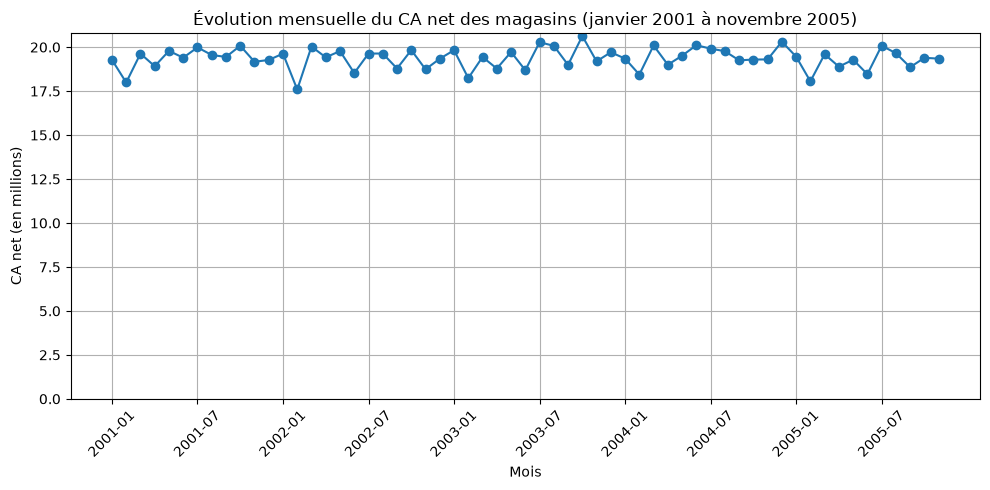

In [8]:
import matplotlib.pyplot as plt
from pathlib import Path

Path("../visualisations").mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10,5))

plt.plot(pdf_mois["mois"], pdf_mois["ca_net_millions"], marker="o")
plt.title("Évolution mensuelle du CA net des magasins (janvier 2001 à novembre 2005)")
plt.xlabel("Mois")
plt.ylabel("CA net (en millions)")
plt.xticks(pdf_mois["mois"][::6], rotation=45)
plt.ylim(bottom=0)

plt.grid(True)
plt.tight_layout()
plt.savefig("../visualisations/visualisation_1.png", dpi=150, bbox_inches="tight")

plt.show()

**Source** : Gold ventes_mensuelles (HDFS, Jour 3). On prend en compte seulement les ventes en magasins, pas les ventes web.
Le jeu de données TPCx-BB est synthétique. Le mois de décembre 2005 est retiré du graphique car incomplet, et enfin la devise du CA est inconnue.

**Résultat** : on voit que le CA reste à peu près stable, et ne descend jamais en-dessous de 17.5M. Aucun tendance à la hausse ou à la baisse n'apparaît.

**Interprétation** : on voit que les creux du graphique tombent chaque année en février. On pourrait croire à un lien de causalité, mais nous reviendrons sur cela dans les limites.

**Limites** : le nombre de ticket suit le nombre de jours du mois, la baisse en février vient donc de la durée du mois. De plus, les données présentées sont synthétiques, les ventes web et les retours sont absents.

## Analyse 2 : comparaison des magasins
Période : toutes les ventes du Silver (de janvier 2001 au 13/12/2005), identique pour les 12 magasins

In [9]:
ventes_par_magasin = (
    df_ventes
    .groupBy("ss_store_sk")
    .agg(
        F.sum("ss_net_paid").alias("ca_net"),
        F.countDistinct("ss_ticket_number").alias("nb_transactions")
    )
    .withColumn("panier_moyen", F.round(F.col("ca_net") / F.col("nb_transactions"), 2))
    .withColumn("ca_net_millions", F.round(F.col("ca_net") / 1000000, 2))
    .orderBy(F.desc("ca_net"))
)

ventes_par_magasin.show()

pdf_ventes = ventes_par_magasin.toPandas()

+-----------+-------------------+---------------+------------+---------------+
|ss_store_sk|             ca_net|nb_transactions|panier_moyen|ca_net_millions|
+-----------+-------------------+---------------+------------+---------------+
|          7|9.895013776000008E7|           7645|    12943.12|          98.95|
|          4|9.677010559000027E7|           7462|    12968.39|          96.77|
|          9|9.674835668000017E7|           7435|    13012.56|          96.75|
|          0|9.672785194000043E7|           7456|    12973.16|          96.73|
|          8|9.657862288999999E7|           7414|    13026.52|          96.58|
|          3|9.606399059000029E7|           7396|    12988.64|          96.06|
|          1|9.592984465999983E7|           7422|    12925.07|          95.93|
|         11| 9.56078434800001E7|           7449|    12834.99|          95.61|
|          6|9.475117308000001E7|           7284|    13008.12|          94.75|
|         10|9.426397755000043E7|           7409|   

/home/ubuntu/retail-intelligence/tp3/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


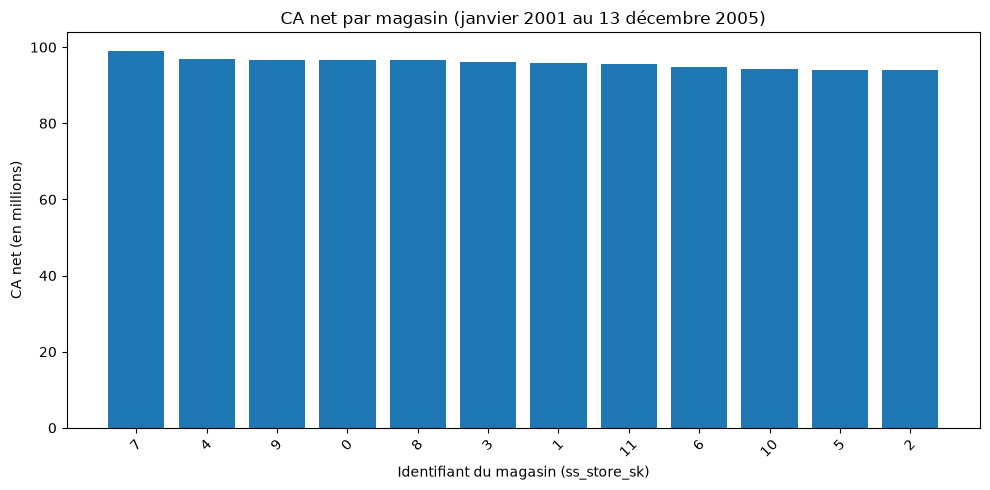

In [10]:
plt.figure(figsize=(10, 5))

plt.bar(
    pdf_ventes["ss_store_sk"].astype(str),
    pdf_ventes["ca_net_millions"]
)

plt.title("CA net par magasin (janvier 2001 au 13 décembre 2005)")
plt.xlabel("Identifiant du magasin (ss_store_sk)")
plt.ylabel("CA net (en millions)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../visualisations/visualisation_2.png", dpi=150, bbox_inches="tight")
plt.show()

**Source** : Silver store_sales (HDFS, Jour 3), regroupé par ss_store_sk.
Le jeu de données TPCx-BB est synthétique et la devise du CA est inconnue.

**Résultat** : le magasin 7 est en tête, avec un CA d'environ 98 millions, le magasin 2 est dernier. L'écart reste assez faible visuellement.

**Interprétation** : comme ont peut le voir dans tableau de la cellule précédente, le magasin 7 est celui qui possède le plus de tickets (7645), mais un panier moyen en dessous de la médiane (mediane ~= 12 955). Son avance vient donc de son nombre élebé de transactions.

**Limites** : il nous manque pas mal d'informations sur les magasins pour aider à la décision : on n'a pas l'emplacement, la surface ou les horaires d'ouverture des magasins par exemple.

## Export des résultats (preuves/uc08)

In [13]:
Path("../preuves/uc08").mkdir(parents=True, exist_ok=True)

df_kpi.toPandas().to_csv("../preuves/uc08/01_kpi_mensuels.csv", index=False)

df_ventes.select("ss_net_paid", "ss_quantity").summary().toPandas().to_csv("../preuves/uc08/02_statistiques_lignes.csv", index=False)

df_tickets.select("montant_ticket", "lignes_par_ticket").summary().toPandas().to_csv("../preuves/uc08/03_statistiques_tickets.csv", index=False)

pdf_ventes.to_csv("../preuves/uc08/04_analyse2_magasins.csv", index=False)

/home/ubuntu/retail-intelligence/tp3/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
